Бизнес-кейс: «Анализ эффективности ремонтных бригад на заводе»

Ситуация: На заводе есть 3 ремонтные бригады (Бригада А, Б, В). Они чинят станки.
Руководство внедрило в марте новую систему мотивации для Бригады В и просит проверить, стала ли она работать быстрее.

1. Загружаем данные от SQL

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Загрузка данных
df_repairs=pd.read_csv('repairs_stats.csv')
print("Данные для анализа:")
print(df_repairs)

Данные для анализа:
     Бригада  Месяц ремонта  Кол-во ремонтов в месяце  \
0  Бригада А              1                         2   
1  Бригада Б              3                         1   
2  Бригада А              3                         1   
3  Бригада В              1                         1   
4  Бригада В              2                         1   
5  Бригада В              3                         1   
6  Бригада Б              1                         1   
7  Бригада Б              2                         1   
8  Бригада А              2                         1   

   среднее время ремонта, ч  Средняя стоимость  
0                         4              16500  
1                         6              19500  
2                         4              14000  
3                         5              17000  
4                         5              17000  
5                         3              12000  
6                         5              20000  
7                

In [17]:
# 2. Переименовываем столбцы
df_repairs.columns = ['team','month','count','avg_hours','avg_cost']
print("Данные для анализа:")
print(df_repairs)

Данные для анализа:
        team  month  count  avg_hours  avg_cost
0  Бригада А      1      2          4     16500
1  Бригада Б      3      1          6     19500
2  Бригада А      3      1          4     14000
3  Бригада В      1      1          5     17000
4  Бригада В      2      1          5     17000
5  Бригада В      3      1          3     12000
6  Бригада Б      1      1          5     20000
7  Бригада Б      2      1          5     21000
8  Бригада А      2      1          4     16000


2. Проверяем гипотезу (А/В тест)

Сравниваем бригаду В в марте с остальными бригадами

In [18]:
# 3. Отфильтруем данные за март
march_data=df_repairs[df_repairs['month']==3]
# 4. Отделим бригаду В (тест) от остальных (контроль)
group_test=march_data[march_data['team']=='Бригада В']['avg_hours']
group_control=march_data[march_data['team']!='Бригада В']['avg_hours']

print(f"Среднее время бригады В в марте: {group_test.mean():.1F} ч.")
print(f"Среднее время бригады A, Б в марте: {group_control.mean():.1F} ч.")

Среднее время бригады В в марте: 3.0 ч.
Среднее время бригады A, Б в марте: 5.0 ч.


In [19]:
# 4. Проводим t-тест (проверяем, значима ли разница)
#equal_var=False, т.к. выборки маленькие и дисперсия может отличаться
t_stat, p_value=stats.ttest_ind(group_test,group_control,equal_var=False)

print(f"\nt-статистика: {t_stat:.3F}")
print(f"\np-value: {p_value:.4F}")


t-статистика: NAN

p-value: NAN


In [20]:
# 5. Интерполяция
if p_value<0.05:
    print("Вывод: разница статистически значима! Мотивация сработала.")
else:
    print("Вывод: разница не значима! Возможно, это случайность")

Вывод: разница не значима! Возможно, это случайность


3. Сравним бригаду В до и после внедрения мотивации

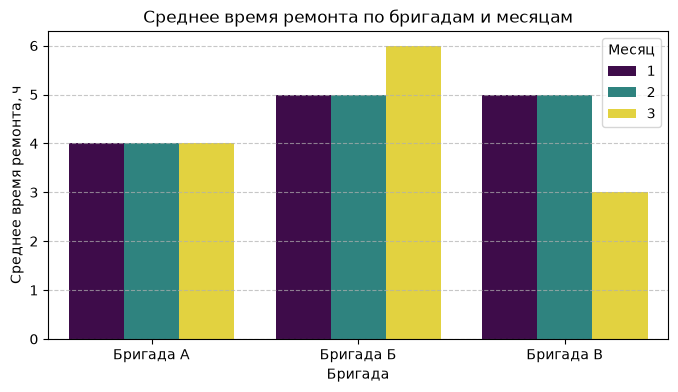

In [22]:
# 6. Строим столбчатую диаграмму: время ремонта по бригадам и месяцам
plt.figure(figsize=(8, 4))
sns.barplot(data=df_repairs, x='team', y='avg_hours',hue='month',palette='viridis')

plt.title('Среднее время ремонта по бригадам и месяцам')
plt.xlabel('Бригада')
plt.ylabel('Среднее время ремонта, ч')
plt.legend(title='Месяц')
plt.grid(axis='y',linestyle='--',alpha=0.7)
plt.show()

Выводы по анализу ремонтных бригад:

1. **Бригада А** показывает стабильное средне время ремонта (4 часа) в каждом месяце. Надежная бригада с предсказуемым результатом.
2. **Бригада Б** самая медленная (5-6 часов). Среднее время ремонта в марте выросло до 6 часов. Требуется дополнительная проверка ее загрузки.
3. **Бригада В** в январе-феврале работала в среднем по 5 часов. После внедрения мотивации в марте **время ремонта сократилось до 3-х часов**.

**Вывод по А/B тесту**
Статистический тест (t-тест) не смог показать значимость из-за слишком малой выборки в марте (всего 3 ремонта). Однако визуальный анализ графика демонстрирует положительный эффект мотивации для Бригады В. Для подтверждения гипотезы рекомендуется собрать больше данных за 2-3 месяца